# QuoteCaster speaker embedding fine-tuning
One readable notebook: labels → fixed sequence split → contextual quote inputs → last-four-layer triplet training → held-out embedding evaluation and plots. **You run the notebook in godfather.venv.** No classifier, projection head or speaker clustering is added.

All supervised triplets/comparisons stay inside one sequence. Character IDs are local to that sequence; UNKNOWN/NARRATION remain in transcript context but are never training/validation targets. Input text never contains GT speaker labels. Empty pages remain in context as page markers.

The local checkpoint README confirms `last_hidden_state[:, 0, :]` and single-string `context [SEP] quote` tokenization. Its example does not normalize embeddings; `NORMALIZE=False` preserves that behavior. If changed, mining/loss/validation all use the same representation. Margin 0.3 is an experiment setting, not a proven optimum.

First run creates token-input caches, split/config files and outputs. Training starts only in the labelled training cell. Rerunning training starts fresh from the pretrained model if you run top to bottom; choose another OUTPUT to preserve an earlier experiment.

## 1. Paths and settings

In [1]:
import os
os.environ['HF_HUB_OFFLINE']='1';os.environ['TRANSFORMERS_OFFLINE']='1'
import json,re,random,math,hashlib,gc
from pathlib import Path
from collections import Counter
from contextlib import nullcontext
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import AutoModel,AutoTokenizer,get_linear_schedule_with_warmup
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT=Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi/FINETUNING-EXPERMENTS/QuoteCaster_Finetuning')
LABELS=Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi/TaskData/development/labels.jsonl')
MODEL_PATH=Path('C:/MODELS/quote-caster-encoder')
OUTPUT=ROOT/'outputs'
SEED=42
VAL_FRACTION=0.20
TRAIN_LAYERS=[8,9,10,11]
LR=2e-5
WEIGHT_DECAY=0.01
MARGIN=0.3
MAX_EPOCHS=10
PATIENCE=3
MAX_TOKENS=512
ENCODE_BATCH_SIZE=4
ACCUMULATION_STEPS=1
WARMUP_FRACTION=0.10
GRAD_CLIP=1.0
NORMALIZE=False
GRADIENT_CHECKPOINTING=True
SMOKE_TEST=True
BOOTSTRAP_REPEATS=2000
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_BF16=DEVICE.type=='cuda' and torch.cuda.is_bf16_supported()
for folder in [OUTPUT,OUTPUT/'plots',OUTPUT/'checkpoints']:folder.mkdir(parents=True,exist_ok=True)


def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
seed_all(SEED)


def file_hash(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def fingerprint(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=True,allow_nan=False).encode()).hexdigest()


def save_json(path,value):
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')


def autocast_context():
    return torch.autocast(device_type='cuda',dtype=torch.bfloat16) if USE_BF16 else nullcontext()


assert MODEL_PATH.is_dir() and (MODEL_PATH/'model.safetensors').is_file(),'Finish the local QuoteCaster download first'
assert LABELS.is_file(),LABELS
assert MARGIN>0 and ENCODE_BATCH_SIZE>=1 and ACCUMULATION_STEPS>=1
assert MODEL_PATH.resolve() not in (OUTPUT/'checkpoints').resolve().parents,'Keep outputs outside the pretrained model folder'
print('Device:',DEVICE,'| BF16:',USE_BF16,'| Model:',MODEL_PATH)


Device: cuda | BF16: True | Model: C:\MODELS\quote-caster-encoder


## 2. Dataset and saved 80/20 sequence split
Counts are calculated from the file. Keep original text/page order, including empty pages. Unknown roles are context only. An eligible triplet sequence needs a repeated known speaker and at least one different known speaker.

In [2]:
raw_sequences=[json.loads(line) for line in LABELS.read_text(encoding='utf-8').splitlines() if line.strip()]
assert len({s['sequence_id'] for s in raw_sequences})==len(raw_sequences),'Duplicate sequence IDs'


def known_speaker(value):return isinstance(value,str) and re.fullmatch(r'character[1-9][0-9]*',value) is not None


sequences=[]
for source in raw_sequences:
    assert len(source['pages'])==3,source['sequence_id']
    entries=[];pages=[];index=0
    for page_number,page in enumerate(source['pages'],1):
        copied=[]
        for local_index,entry in enumerate(page):
            assert isinstance(entry['text'],str),'Text must be a string'
            row=dict(sequence_id=source['sequence_id'],page_number=page_number,
                page_dialogue_index=local_index,dialogue_index=index,text=entry['text'],speaker_id=entry['speaker'])
            entries.append(row);copied.append(row);index+=1
        pages.append(copied)
    counts=Counter(e['speaker_id'] for e in entries if e['text'].strip() and known_speaker(e['speaker_id']))
    sequences.append(dict(sequence_id=source['sequence_id'],pages=pages,entries=entries,
        context='\n'.join(f'[PAGE {i+1}]\n'+'\n'.join(e['text'] for e in page) for i,page in enumerate(pages)),
        eligible=len(counts)>=2 and max(counts.values(),default=0)>=2,speaker_counts=dict(counts)))
lengths=[len(s['entries']) for s in sequences]
summary=dict(sequences=len(sequences),text_entries=sum(lengths),
    narration=sum(e['speaker_id']=='NARRATION' for s in sequences for e in s['entries']),
    unknown=sum(e['speaker_id']=='UNKNOWN' for s in sequences for e in s['entries']),
    empty_texts=sum(not e['text'].strip() for s in sequences for e in s['entries']),
    empty_pages=sum(not p for s in sequences for p in s['pages']),
    eligible_speakers=sum(len(s['speaker_counts']) for s in sequences),
    triplet_eligible_sequences=sum(s['eligible'] for s in sequences),
    sequence_lengths=dict(min=min(lengths),median=float(np.median(lengths)),max=max(lengths)),
    exclusions='Only nonempty characterN entries are embedding targets; other text remains context')
save_json(OUTPUT/'dataset_summary.json',summary);display(pd.DataFrame([summary]))

split_path=OUTPUT/'split_manifest.json'
ids=sorted(s['sequence_id'] for s in sequences)
if split_path.is_file():
    split=json.loads(split_path.read_text(encoding='utf-8'))
    assert split['labels_sha256']==file_hash(LABELS),'Dataset changed; use a new OUTPUT'
    assert split['seed']==SEED and split['val_fraction']==VAL_FRACTION,'Split settings changed; use a new OUTPUT'
else:
    shuffled=ids.copy();random.Random(SEED).shuffle(shuffled)
    n_val=max(1,round(len(ids)*VAL_FRACTION))
    split=dict(seed=SEED,val_fraction=VAL_FRACTION,labels_sha256=file_hash(LABELS),
        train=sorted(shuffled[n_val:]),validation=sorted(shuffled[:n_val]))
    save_json(split_path,split)
assert set(split['train']).isdisjoint(split['validation'])
assert set(split['train'])|set(split['validation'])==set(ids)
train_sequences=[s for s in sequences if s['sequence_id'] in split['train']]
val_sequences=[s for s in sequences if s['sequence_id'] in split['validation']]
assert any(s['eligible'] for s in train_sequences) and any(s['eligible'] for s in val_sequences)
display(pd.DataFrame([dict(split=name,sequences=len(items),triplet_eligible=sum(s['eligible'] for s in items))
    for name,items in [('train',train_sequences),('validation',val_sequences)]]))


,sequences,text_entries,narration,unknown,empty_texts,empty_pages,eligible_speakers,triplet_eligible_sequences,sequence_lengths,exclusions
0,80,1753,76,34,0,10,258,76,"{'min': 0, 'median': 23.0, 'max': 47}",Only nonempty characterN entries are embedding...


,split,sequences,triplet_eligible
0,train,64,62
1,validation,16,14


## 3. Local tokenizer and target-specific input cache
Use the whole ordered transcript where it fits. Otherwise take a centered token window around the target’s location in that transcript. Page/dialogue markers contain no speaker identities. Reserve quote tokens before context; only quotes longer than the token budget themselves are truncated and counted. Token types are all zero, matching the original single-string inference convention.

In [3]:
tokenizer=AutoTokenizer.from_pretrained(str(MODEL_PATH),local_files_only=True)
TOKENIZER_ID={p.name:[p.stat().st_size,p.stat().st_mtime_ns,file_hash(p)] for p in MODEL_PATH.iterdir()
    if p.is_file() and p.suffix in ['.json','.txt']}


def centered_window(tokens,center,budget):
    if budget<=0:return []
    if len(tokens)<=budget:return tokens
    start=max(0,min(len(tokens)-budget,int(center)-budget//2))
    return tokens[start:start+budget]


def tokenize_sequence(sequence):
    context_ids=[];centers={}
    for number,page in enumerate(sequence['pages'],1):
        context_ids+=tokenizer.encode(f'[PAGE {number}]\n',add_special_tokens=False)
        for entry in page:
            start=len(context_ids)
            context_ids+=tokenizer.encode('[DIALOGUE] '+entry['text']+'\n',add_special_tokens=False)
            centers[entry['dialogue_index']]=(start+len(context_ids))//2
    items=[];speaker_names={}
    for entry in sequence['entries']:
        if not entry['text'].strip() or not known_speaker(entry['speaker_id']):continue
        quote=tokenizer.encode(entry['text'],add_special_tokens=False) or [tokenizer.unk_token_id]
        truncated=len(quote)>MAX_TOKENS-3;quote=quote[:MAX_TOKENS-3]
        context=centered_window(context_ids,centers[entry['dialogue_index']],MAX_TOKENS-3-len(quote))
        ids=[tokenizer.cls_token_id]+context+[tokenizer.sep_token_id]+quote+[tokenizer.sep_token_id]
        label=speaker_names.setdefault(entry['speaker_id'],len(speaker_names))
        items.append(dict(ids=ids,label=label,dialogue_index=entry['dialogue_index'],quote_truncated=truncated))
    return dict(sequence_id=sequence['sequence_id'],eligible=sequence['eligible'],items=items)


input_signature=fingerprint(dict(labels=file_hash(LABELS),tokenizer=TOKENIZER_ID,max_tokens=MAX_TOKENS,
    format='single_string_cls_context_sep_quote_sep_zero_token_types',window='centered_target_v1'))
cache_path=OUTPUT/'tokenized_sequences.pt'
saved=torch.load(cache_path,map_location='cpu',weights_only=True) if cache_path.is_file() else None
if saved and saved['signature']==input_signature:tokenized=saved['sequences'];print('Reused token inputs')
else:
    tokenized=[tokenize_sequence(s) for s in sequences]
    torch.save(dict(signature=input_signature,sequences=tokenized),cache_path);print('Created token inputs')
train_data=[s for s in tokenized if s['sequence_id'] in split['train']]
val_data=[s for s in tokenized if s['sequence_id'] in split['validation']]
assert all(len(item['ids'])<=MAX_TOKENS for s in tokenized for item in s['items'])
print('Embedding targets:',sum(len(s['items']) for s in tokenized),
    '| Long target quotes truncated:',sum(item['quote_truncated'] for s in tokenized for item in s['items']))


Created token inputs
Embedding targets: 1643 | Long target quotes truncated: 0


## 4. Load QuoteCaster; train only layers 8–11
Keep token embeddings, lower layers and the unused pooler frozen. CLS extraction has no added head. Non-reentrant gradient checkpointing reduces memory when a whole sequence’s embeddings remain connected for triplet loss.

In [4]:
model=AutoModel.from_pretrained(str(MODEL_PATH),local_files_only=True,attn_implementation='sdpa').to(DEVICE)
assert model.config.num_hidden_layers==12 and model.config.hidden_size==768
assert MAX_TOKENS<=model.config.max_position_embeddings
model.requires_grad_(False)
for index in TRAIN_LAYERS:model.encoder.layer[index].requires_grad_(True)
if GRADIENT_CHECKPOINTING:model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
trainable=[p for p in model.parameters() if p.requires_grad]
print('Trainable:',sum(p.numel() for p in trainable),'| Frozen:',sum(p.numel() for p in model.parameters() if not p.requires_grad))
print('Trainable encoder layers:',TRAIN_LAYERS,'| Normalize embeddings:',NORMALIZE)
MODEL_ID={p.name:[p.stat().st_size,p.stat().st_mtime_ns] for p in MODEL_PATH.iterdir()
    if p.is_file() and p.suffix in ['.json','.bin','.safetensors']}
CONFIG=dict(model=str(MODEL_PATH),model_files=MODEL_ID,labels=str(LABELS),labels_sha256=file_hash(LABELS),
    local_model_card_sha256=file_hash(MODEL_PATH/'README.md'),seed=SEED,split=split,train_layers=TRAIN_LAYERS,
    lr=LR,weight_decay=WEIGHT_DECAY,margin=MARGIN,max_epochs=MAX_EPOCHS,patience=PATIENCE,
    normalize=NORMALIZE,distance='Euclidean p=2 eps=0',pool='last_hidden_state[:,0,:]',
    max_tokens=MAX_TOKENS,input_signature=input_signature,encode_batch_size=ENCODE_BATCH_SIZE,
    accumulation_steps=ACCUMULATION_STEPS,warmup_fraction=WARMUP_FRACTION,grad_clip=GRAD_CLIP,
    bf16=USE_BF16,gradient_checkpointing=GRADIENT_CHECKPOINTING,
    torch_version=torch.__version__,transformers_version=__import__('transformers').__version__)
save_json(OUTPUT/'experiment_config.json',CONFIG)


def encode_sequence(sequence,training=False):
    vectors=[]
    with torch.set_grad_enabled(training):
        for start in range(0,len(sequence['items']),ENCODE_BATCH_SIZE):
            items=sequence['items'][start:start+ENCODE_BATCH_SIZE]
            length=max(len(item['ids']) for item in items)
            ids=torch.full((len(items),length),tokenizer.pad_token_id,dtype=torch.long,device=DEVICE)
            attention=torch.zeros_like(ids)
            for i,item in enumerate(items):
                ids[i,:len(item['ids'])]=torch.tensor(item['ids'],device=DEVICE);attention[i,:len(item['ids'])]=1
            with autocast_context():
                outputs=model(input_ids=ids,attention_mask=attention,token_type_ids=torch.zeros_like(ids))
                cls=outputs.last_hidden_state[:,0,:].float()
            vectors.append(F.normalize(cls,p=2,dim=-1) if NORMALIZE else cls)
        z=torch.cat(vectors) if vectors else torch.empty((0,768),device=DEVICE)
    assert torch.isfinite(z).all(),'Invalid embeddings'
    return z


Trainable: 28351488 | Frozen: 81130752
Trainable encoder layers: [8, 9, 10, 11] | Normalize embeddings: False


## 5. Online semi-hard mining and triplet loss
Mine only this sequence, using detached current embeddings. Semi-hard first, nearest hard fallback second, otherwise skip. The loss uses the original gradient-connected vectors. eps=0 matches torch.cdist’s Euclidean convention.

In [5]:
def mine_triplets(embeddings,labels,margin):
    distances=torch.cdist(embeddings.detach().float(),embeddings.detach().float(),p=2).cpu()
    labels=torch.as_tensor(labels,dtype=torch.long).cpu()
    triplets=[];stats=dict(ap_pairs=0,semi_hard=0,hard=0,skipped=0,skipped_no_negative=0,skipped_easy=0)
    for anchor in range(len(labels)):
        positives=torch.where(labels==labels[anchor])[0].tolist()
        negatives=torch.where(labels!=labels[anchor])[0]
        for positive in positives:
            if positive==anchor:continue
            stats['ap_pairs']+=1
            if not len(negatives):
                stats['skipped']+=1;stats['skipped_no_negative']+=1;continue
            dap=distances[anchor,positive];dan=distances[anchor,negatives]
            candidates=negatives[(dan>dap)&(dan<dap+margin)]
            if len(candidates):kind='semi_hard'
            else:
                candidates=negatives[dan<=dap];kind='hard'
            if not len(candidates):
                stats['skipped']+=1;stats['skipped_easy']+=1;continue
            negative=int(candidates[torch.argmin(distances[anchor,candidates])])
            triplets.append((anchor,positive,negative));stats[kind]+=1
    assert stats['semi_hard']+stats['hard']+stats['skipped']==stats['ap_pairs']
    return triplets,stats


def triplet_loss(embeddings,triplets):
    indices=torch.tensor(triplets,dtype=torch.long,device=embeddings.device)
    return F.triplet_margin_loss(embeddings[indices[:,0]],embeddings[indices[:,1]],embeddings[indices[:,2]],
        margin=MARGIN,p=2,eps=0.0,reduction='mean')


## 6. Validation on all within-sequence comparisons
No validation mining or difficulty selection. Use every ordered eligible A/P/N combination and every unordered distinct-utterance pair. Macro-average per-sequence metrics; report excluded/eligible counts. Pair distances remain on CPU for plotting, never attached to a training graph.

In [6]:
def sequence_metrics(embeddings,labels,sequence_id,margin):
    labels=np.asarray(labels,dtype=np.int64)
    d=torch.cdist(embeddings.detach().float().cpu(),embeddings.detach().float().cpu()).numpy()
    assert np.isfinite(d).all()
    total=correct=satisfied=0
    for anchor in range(len(labels)):
        positive=np.flatnonzero(labels==labels[anchor]);positive=positive[positive!=anchor]
        negative=np.flatnonzero(labels!=labels[anchor])
        for p in positive:
            total+=len(negative);correct+=int((d[anchor,p]<d[anchor,negative]).sum())
            satisfied+=int((d[anchor,p]+margin<=d[anchor,negative]).sum())
    left,right=np.triu_indices(len(labels),1)
    same=labels[left]==labels[right];pair_distances=d[left,right]
    pos=pair_distances[same];neg=pair_distances[~same]
    auc=float(roc_auc_score(same.astype(int),-pair_distances)) if len(pos) and len(neg) else None
    row=dict(sequence_id=sequence_id,targets=len(labels),pair_count=len(left),positive_pairs=len(pos),negative_pairs=len(neg),
        triplet_count=total,triplet_accuracy=correct/total if total else None,
        pairwise_auc=auc,margin_satisfaction=satisfied/total if total else None,
        positive_mean=float(pos.mean()) if len(pos) else None,negative_mean=float(neg.mean()) if len(neg) else None,
        positive_median=float(np.median(pos)) if len(pos) else None,negative_median=float(np.median(neg)) if len(neg) else None,
        skip_reason='' if total else 'No repeated known speaker with a different known speaker')
    return row,pos,neg


METRIC_KEYS=['triplet_accuracy','pairwise_auc','margin_satisfaction','positive_mean','negative_mean','positive_median','negative_median']


@torch.inference_mode()
def validate(data):
    model.eval();rows=[];positive=[];negative=[]
    for sequence in data:
        z=encode_sequence(sequence,training=False)
        row,pos,neg=sequence_metrics(z,[item['label'] for item in sequence['items']],sequence['sequence_id'],MARGIN)
        rows.append(row);positive.extend(pos.tolist());negative.extend(neg.tolist())
    macro={key:float(np.mean([row[key] for row in rows if row[key] is not None]))
        if any(row[key] is not None for row in rows) else None for key in METRIC_KEYS}
    macro.update(sequences_evaluated=len(rows),triplet_sequences=sum(row['triplet_count']>0 for row in rows),
        auc_sequences=sum(row['pairwise_auc'] is not None for row in rows))
    assert macro['triplet_accuracy'] is not None and macro['pairwise_auc'] is not None
    return macro,rows,dict(positive=np.asarray(positive),negative=np.asarray(negative))


## 7. Single-sequence smoke test
Forward/backward only; no optimizer step. If all negatives are easy, use one valid structural triplet solely to test gradients. Clear gradients and reseed afterward.

In [7]:
if SMOKE_TEST:
    sample=next(s for s in train_data if s['eligible'])
    model.train();model.zero_grad(set_to_none=True)
    z=encode_sequence(sample,training=True);labels=[i['label'] for i in sample['items']]
    triplets,_=mine_triplets(z,labels,MARGIN)
    if not triplets:
        triplets=[next((a,p,n) for a in range(len(labels)) for p in range(len(labels)) for n in range(len(labels))
            if a!=p and labels[a]==labels[p] and labels[a]!=labels[n])]
        print('Smoke test only: structural triplet fallback')
    loss=triplet_loss(z,triplets);assert torch.isfinite(loss)
    loss.backward()
    gradients=[p.grad for p in trainable if p.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients)
    print('Smoke passed:',sample['sequence_id'],'| loss:',float(loss.detach()))
    model.zero_grad(set_to_none=True);del z,loss,gradients;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    seed_all(SEED)


Smoke passed: seq_7db7a000adeceacf | loss: 0.30141445994377136


## 8. Pretrained baseline — epoch 0
Evaluate every validation sequence before training. Save the baseline as the first best candidate in this experiment, never in the downloaded model directory. Best selection uses macro triplet accuracy; AUC breaks exact ties.

In [8]:
def save_checkpoint(name,epoch,metrics):
    folder=OUTPUT/'checkpoints'/name;folder.mkdir(parents=True,exist_ok=True)
    assert folder.resolve()!=MODEL_PATH.resolve()
    model.save_pretrained(folder,safe_serialization=True);tokenizer.save_pretrained(folder)
    save_json(folder/'metadata.json',dict(epoch=epoch,metrics=metrics,config=CONFIG))


def better(metrics,best):
    gain=metrics['triplet_accuracy']-best['triplet_accuracy']
    return gain>1e-12 or (abs(gain)<=1e-12 and metrics['pairwise_auc']>best['pairwise_auc']+1e-12)


baseline_metrics,baseline_rows,baseline_distances=validate(val_data)
validation_history=[dict(epoch=0,**baseline_metrics)]
validation_rows=[dict(epoch=0,**row) for row in baseline_rows]
training_history=[];best_metrics=baseline_metrics.copy();best_epoch=0
save_json(OUTPUT/'baseline_metrics.json',baseline_metrics)
np.savez(OUTPUT/'baseline_distances.npz',**baseline_distances)
pd.DataFrame(validation_history).to_csv(OUTPUT/'validation_history.csv',index=False)
pd.DataFrame(validation_rows).to_csv(OUTPUT/'validation_by_sequence.csv',index=False)
save_checkpoint('best',0,baseline_metrics)
display(pd.DataFrame(validation_history))


,epoch,triplet_accuracy,pairwise_auc,margin_satisfaction,positive_mean,negative_mean,positive_median,negative_median,sequences_evaluated,triplet_sequences,auc_sequences
0,0,0.549923,0.5217,0.377273,2.625084,2.693001,2.556554,2.590229,16,14,14


## 9. Sequence training helpers
One sequence-average loss per update; logged loss is weighted by selected triplet count. Shuffle sequences only. Count skipped A/P pairs separately from skipped sequences. Accumulation corrects the final partial batch. Warmup uses the maximum possible updates; skipped sequences do not advance the scheduler.

In [9]:
optimizer=torch.optim.AdamW(trainable,lr=LR,weight_decay=WEIGHT_DECAY)
max_updates=MAX_EPOCHS*math.ceil(sum(s['eligible'] for s in train_data)/ACCUMULATION_STEPS)
scheduler=get_linear_schedule_with_warmup(optimizer,int(max_updates*WARMUP_FRACTION),max(1,max_updates))


def update_parameters(accumulated):
    if accumulated<ACCUMULATION_STEPS:
        for p in trainable:
            if p.grad is not None:p.grad.mul_(ACCUMULATION_STEPS/accumulated)
    norm=torch.nn.utils.clip_grad_norm_(trainable,GRAD_CLIP,error_if_nonfinite=True)
    optimizer.step();scheduler.step();optimizer.zero_grad(set_to_none=True)
    return float(norm)


def train_epoch(epoch):
    model.train();optimizer.zero_grad(set_to_none=True)
    order=list(range(len(train_data)));random.Random(SEED+epoch).shuffle(order)
    totals=dict(ap_pairs=0,semi_hard=0,hard=0,skipped=0,skipped_no_negative=0,skipped_easy=0)
    selected=skipped_sequences=updates=accumulated=0;loss_sum=0.;norms=[]
    for position,index in enumerate(order,1):
        sequence=train_data[index];labels=[item['label'] for item in sequence['items']]
        if not sequence['eligible']:
            ap=sum(c*(c-1) for c in Counter(labels).values())
            totals['ap_pairs']+=ap;totals['skipped']+=ap;totals['skipped_no_negative']+=ap
            skipped_sequences+=1;continue
        z=encode_sequence(sequence,training=True)
        triplets,stats=mine_triplets(z,labels,MARGIN)
        for key in totals:totals[key]+=stats[key]
        if not triplets:skipped_sequences+=1;del z;continue
        loss=triplet_loss(z,triplets);assert torch.isfinite(loss),'Nonfinite loss'
        loss_sum+=float(loss.detach())*len(triplets);selected+=len(triplets)
        (loss/ACCUMULATION_STEPS).backward();accumulated+=1;del z,loss
        if accumulated==ACCUMULATION_STEPS:
            norms.append(update_parameters(accumulated));updates+=1;accumulated=0
        if position%10==0:print('Epoch',epoch,'| sequences',position,'/',len(order),'| triplets',selected)
    if accumulated:norms.append(update_parameters(accumulated));updates+=1
    ap=totals['ap_pairs'];assert totals['semi_hard']+totals['hard']+totals['skipped']==ap
    return dict(epoch=epoch,train_loss=loss_sum/selected if selected else None,
        selected_triplets=selected,skipped_sequences=skipped_sequences,optimizer_updates=updates,
        semi_hard_rate=totals['semi_hard']/ap if ap else 0.,hard_rate=totals['hard']/ap if ap else 0.,
        skipped_rate=totals['skipped']/ap if ap else 0.,gradient_norm=float(np.mean(norms)) if norms else None,
        learning_rate=optimizer.param_groups[0]['lr'],**totals)


## 10. Train — you run this cell
At most 10 epochs; stop after three validation checks without improvement. All sequence-level validation results are saved each epoch. Best/final checkpoints are separate. No clustering is evaluated.

In [10]:
patience_count=0;last_epoch=0
for epoch in range(1,MAX_EPOCHS+1):
    training=train_epoch(epoch);metrics,rows,_=validate(val_data)
    training_history.append(training);validation_history.append(dict(epoch=epoch,**metrics))
    validation_rows.extend(dict(epoch=epoch,**row) for row in rows)
    pd.DataFrame(training_history).to_csv(OUTPUT/'training_history.csv',index=False)
    pd.DataFrame(validation_history).to_csv(OUTPUT/'validation_history.csv',index=False)
    pd.DataFrame(validation_rows).to_csv(OUTPUT/'validation_by_sequence.csv',index=False)
    if better(metrics,best_metrics):
        best_metrics=metrics.copy();best_epoch=epoch;patience_count=0;save_checkpoint('best',epoch,metrics)
    else:patience_count+=1
    last_epoch=epoch
    display(pd.DataFrame([dict(epoch=epoch,loss=training['train_loss'],
        triplet_accuracy=metrics['triplet_accuracy'],pairwise_auc=metrics['pairwise_auc'],
        margin_satisfaction=metrics['margin_satisfaction'],semi_hard_rate=training['semi_hard_rate'],
        hard_rate=training['hard_rate'],skipped_rate=training['skipped_rate'],
        selected_triplets=training['selected_triplets'],skipped_sequences=training['skipped_sequences'])]))
    if patience_count>=PATIENCE:print('Early stopping; best epoch:',best_epoch);break
save_checkpoint('final',last_epoch,validation_history[-1])
save_json(OUTPUT/'best_checkpoint.json',dict(path=str(OUTPUT/'checkpoints/best'),epoch=best_epoch,metrics=best_metrics))
print('Best epoch:',best_epoch,'| Total selected triplets:',sum(r['selected_triplets'] for r in training_history))


Epoch 1 | sequences 10 / 64 | triplets 1247
Epoch 1 | sequences 20 / 64 | triplets 3645
Epoch 1 | sequences 30 / 64 | triplets 4625
Epoch 1 | sequences 40 / 64 | triplets 7825
Epoch 1 | sequences 50 / 64 | triplets 10791
Epoch 1 | sequences 60 / 64 | triplets 12909


,epoch,loss,triplet_accuracy,pairwise_auc,margin_satisfaction,semi_hard_rate,hard_rate,skipped_rate,selected_triplets,skipped_sequences
0,1,0.384903,0.552709,0.532056,0.327663,0.825306,0.134924,0.039769,13159,2


Epoch 2 | sequences 10 / 64 | triplets 2181
Epoch 2 | sequences 20 / 64 | triplets 2961
Epoch 2 | sequences 30 / 64 | triplets 5809
Epoch 2 | sequences 40 / 64 | triplets 7723
Epoch 2 | sequences 50 / 64 | triplets 9418
Epoch 2 | sequences 60 / 64 | triplets 11636


,epoch,loss,triplet_accuracy,pairwise_auc,margin_satisfaction,semi_hard_rate,hard_rate,skipped_rate,selected_triplets,skipped_sequences
0,2,0.329496,0.551782,0.543702,0.344533,0.86223,0.115076,0.022694,13393,2


Epoch 3 | sequences 10 / 64 | triplets 2010
Epoch 3 | sequences 20 / 64 | triplets 4723
Epoch 3 | sequences 30 / 64 | triplets 6819
Epoch 3 | sequences 40 / 64 | triplets 8503
Epoch 3 | sequences 50 / 64 | triplets 10794
Epoch 3 | sequences 60 / 64 | triplets 11905


...

Epoch 9 | sequences 10 / 64 | triplets 2491
Epoch 9 | sequences 20 / 64 | triplets 4214
Epoch 9 | sequences 30 / 64 | triplets 6042
Epoch 9 | sequences 50 / 64 | triplets 10434
Epoch 9 | sequences 60 / 64 | triplets 11911


,epoch,loss,triplet_accuracy,pairwise_auc,margin_satisfaction,semi_hard_rate,hard_rate,skipped_rate,selected_triplets,skipped_sequences
0,9,0.322354,0.570835,0.568407,0.428579,0.830779,0.113981,0.055239,12947,2


Epoch 10 | sequences 10 / 64 | triplets 2328
Epoch 10 | sequences 20 / 64 | triplets 4774
Epoch 10 | sequences 30 / 64 | triplets 5723
Epoch 10 | sequences 40 / 64 | triplets 7642
Epoch 10 | sequences 50 / 64 | triplets 9379
Epoch 10 | sequences 60 / 64 | triplets 11477


,epoch,loss,triplet_accuracy,pairwise_auc,margin_satisfaction,semi_hard_rate,hard_rate,skipped_rate,selected_triplets,skipped_sequences
0,10,0.323364,0.570133,0.567452,0.430132,0.836106,0.1196,0.044294,13097,3


Best epoch: 8 | Total selected triplets: 131480


## 11. Best versus pretrained + paired sequence bootstrap
Macro sequence metrics are the primary comparison. Bootstrap resamples entire validation sequences, preserving the correlation of pairs/triplets within each sequence. This remains validation evidence, not an independent test result or a clustering result.

In [11]:
model.zero_grad(set_to_none=True)
del optimizer,scheduler,trainable,model;gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()
model=AutoModel.from_pretrained(str(OUTPUT/'checkpoints/best'),local_files_only=True,attn_implementation='sdpa').to(DEVICE).eval()
model.requires_grad_(False)
best_eval,best_rows,best_distances=validate(val_data)
np.savez(OUTPUT/'best_distances.npz',**best_distances)
pd.DataFrame(best_rows).to_csv(OUTPUT/'best_validation_by_sequence.csv',index=False)
report=pd.DataFrame([dict(metric=key,pretrained=baseline_metrics[key],best=best_eval[key],
    change=best_eval[key]-baseline_metrics[key]) for key in METRIC_KEYS])
display(report);report.to_csv(OUTPUT/'final_comparison.csv',index=False)


def paired_sequence_bootstrap(before,after,metric,repeats,seed):
    left={r['sequence_id']:r[metric] for r in before if r[metric] is not None}
    right={r['sequence_id']:r[metric] for r in after if r[metric] is not None}
    ids=sorted(set(left)&set(right))
    if not ids:return None
    differences=np.array([right[sid]-left[sid] for sid in ids]);rng=np.random.default_rng(seed)
    means=differences[rng.integers(0,len(ids),size=(repeats,len(ids)))].mean(axis=1)
    return dict(metric=metric,sequences=len(ids),mean_change=float(differences.mean()),
        lower_95=float(np.quantile(means,.025)),upper_95=float(np.quantile(means,.975)))


intervals=[]
if BOOTSTRAP_REPEATS>0:
    intervals=[paired_sequence_bootstrap(baseline_rows,best_rows,key,BOOTSTRAP_REPEATS,SEED)
        for key in ['triplet_accuracy','pairwise_auc','margin_satisfaction']]
    intervals=[row for row in intervals if row is not None]
    display(pd.DataFrame(intervals));save_json(OUTPUT/'sequence_bootstrap.json',intervals)
save_json(OUTPUT/'final_report.json',dict(best_epoch=best_epoch,baseline=baseline_metrics,best=best_eval,bootstrap=intervals))
print('Held-out macro triplet accuracy improved:',best_eval['triplet_accuracy']>baseline_metrics['triplet_accuracy']+1e-12)
print('Speaker clustering has not been evaluated.')
print('Best model:',OUTPUT/'checkpoints/best');print('Final model:',OUTPUT/'checkpoints/final')


,metric,pretrained,best,change
0,triplet_accuracy,0.549923,0.570911,0.020988
1,pairwise_auc,0.521700,0.570923,0.049222
2,margin_satisfaction,0.377273,0.437935,0.060662
3,positive_mean,2.625084,2.884355,0.259271
4,negative_mean,2.693001,2.962446,0.269444
5,positive_median,2.556554,2.926110,0.369556
6,negative_median,2.590229,3.055485,0.465256


,metric,sequences,mean_change,lower_95,upper_95
0,triplet_accuracy,14,0.020988,-0.022119,0.059832
1,pairwise_auc,14,0.049222,0.009062,0.086225
2,margin_satisfaction,14,0.060662,0.022026,0.097354


Held-out macro triplet accuracy improved: True
Speaker clustering has not been evaluated.
Best model: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\QuoteCaster_Finetuning\outputs\checkpoints\best
Final model: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\QuoteCaster_Finetuning\outputs\checkpoints\final


## 12. Required plots
Save PNGs and display inline. Distance histograms use every known-speaker pair in the same validation sequences, identical bins and density normalization. Histograms pool pairs; reported/model-selection metrics remain sequence-macro.

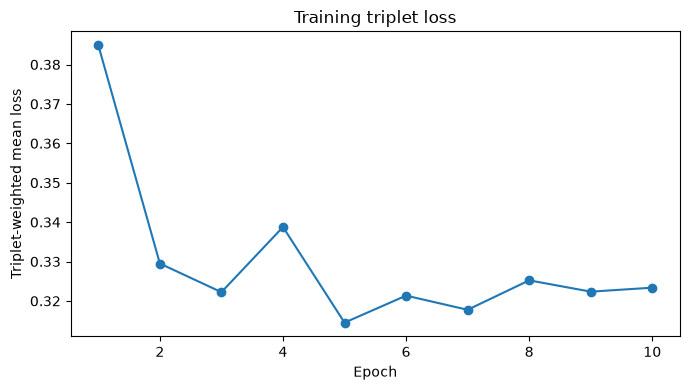

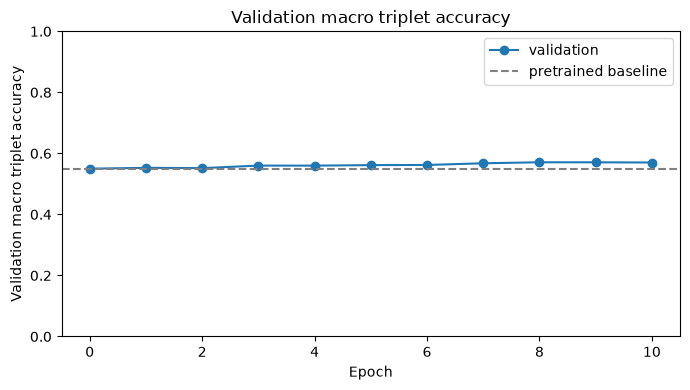

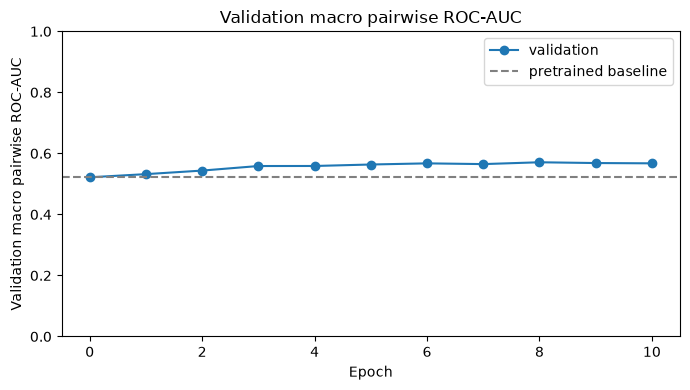

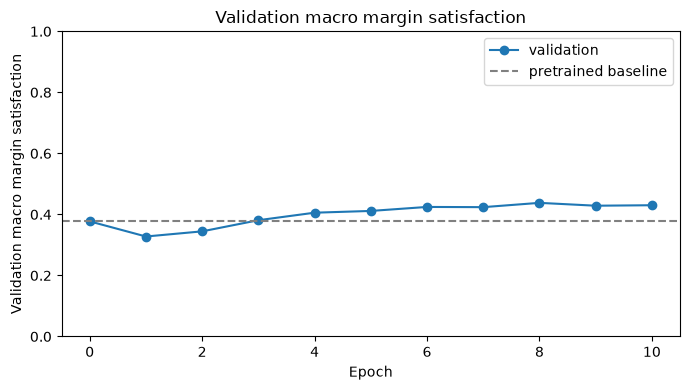

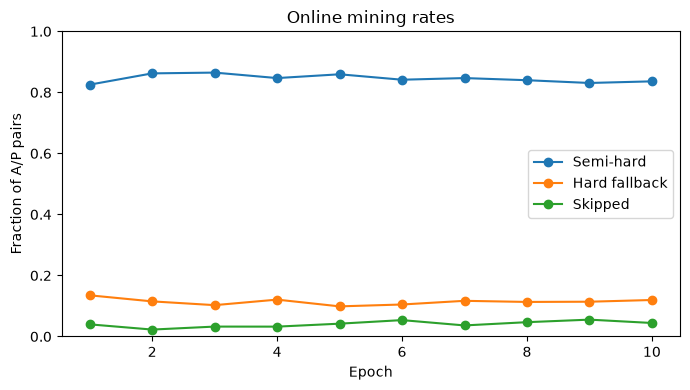

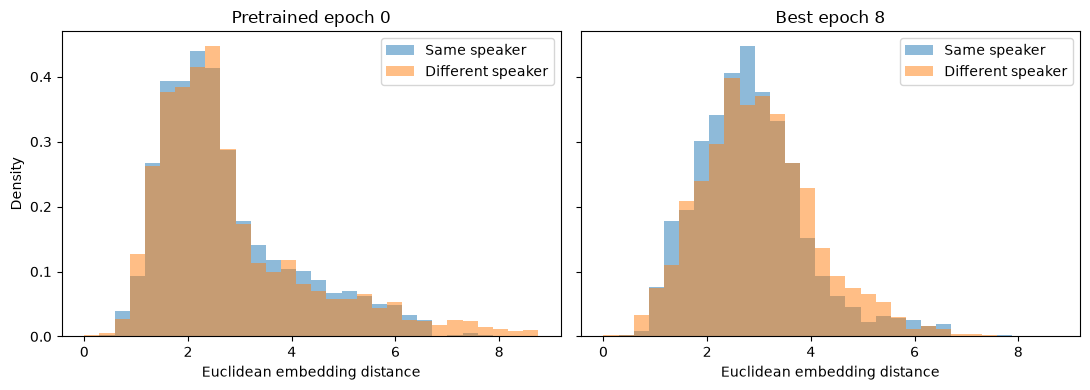

Saved plots: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\QuoteCaster_Finetuning\outputs\plots


In [12]:
train_frame=pd.DataFrame(training_history);val_frame=pd.DataFrame(validation_history)


def finish_plot(filename):
    plt.tight_layout();plt.savefig(OUTPUT/'plots'/filename,dpi=150,bbox_inches='tight')
    plt.show();plt.close()


plt.figure(figsize=(7,4))
if len(train_frame):plt.plot(train_frame['epoch'],train_frame['train_loss'],marker='o')
plt.xlabel('Epoch');plt.ylabel('Triplet-weighted mean loss');plt.title('Training triplet loss')
finish_plot('training_triplet_loss.png')
for key,title in [('triplet_accuracy','Validation macro triplet accuracy'),('pairwise_auc','Validation macro pairwise ROC-AUC'),
                  ('margin_satisfaction','Validation macro margin satisfaction')]:
    plt.figure(figsize=(7,4));plt.plot(val_frame['epoch'],val_frame[key],marker='o',label='validation')
    plt.axhline(baseline_metrics[key],color='grey',linestyle='--',label='pretrained baseline')
    plt.xlabel('Epoch');plt.ylabel(title);plt.ylim(0,1);plt.title(title);plt.legend();finish_plot(key+'.png')
plt.figure(figsize=(7,4))
if len(train_frame):
    for key,label in [('semi_hard_rate','Semi-hard'),('hard_rate','Hard fallback'),('skipped_rate','Skipped')]:
        plt.plot(train_frame['epoch'],train_frame[key],marker='o',label=label)
plt.xlabel('Epoch');plt.ylabel('Fraction of A/P pairs');plt.ylim(0,1);plt.title('Online mining rates');plt.legend()
finish_plot('mining_rates.png')
all_distances=np.concatenate([baseline_distances['positive'],baseline_distances['negative'],best_distances['positive'],best_distances['negative']])
bins=np.linspace(0,max(float(all_distances.max())*1.01,1e-6),31)
fig,axes=plt.subplots(1,2,figsize=(11,4),sharex=True,sharey=True)
for ax,title,distances in [(axes[0],'Pretrained epoch 0',baseline_distances),(axes[1],f'Best epoch {best_epoch}',best_distances)]:
    for key,label,color in [('positive','Same speaker','tab:blue'),('negative','Different speaker','tab:orange')]:
        if len(distances[key]):ax.hist(distances[key],bins=bins,density=True,alpha=.5,label=label,color=color)
    ax.set_title(title);ax.set_xlabel('Euclidean embedding distance');ax.legend()
axes[0].set_ylabel('Density');finish_plot('positive_negative_distances.png')
print('Saved plots:',OUTPUT/'plots')
